# Heart Disease Risk Prediction from Clinical Measurements
## Term Project — Part 1: Data Acquisition, Cleaning, Preprocessing, Feature Engineering and EDA

**Course:** DS5002 Data Science Tools and Techniques (Fall 2026) · **Instructor:** Dr. Asma Ahmad · **TA:** Burhan Hadi Butt
**Group 15:** Raza Ul Mustafa (26L-8030) · Ahmad Ali (26L-8015) · Gohar Maqsood (26L-8033)
**Part 1 prepared by:** Raza Ul Mustafa (26L-8030)

**Project question:** Can 11 clinical and exercise-test measurements predict heart disease with high recall on unseen patients, and does the model still work at a hospital that was not in its training data?

**What this notebook covers (Part 1):**

| Section | Content |
|---|---|
| 1 | Dataset loading and description |
| 2 | Data cleaning: duplicates, missing values (including hidden zeros), outliers |
| 3 | Preprocessing, transformations and the train/test split |
| 4 | Feature engineering and feature selection |
| 5 | Exploratory Data Analysis (EDA) with visualizations |
| 6 | Key observations and insights |
| 7 | Saved outputs for Part 2 |

In [1]:
# Setup: libraries, fixed seed and folder paths
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42                                   # one seed for every random step

RAW = Path("../data/raw")                   # 4 original UCI files
PROC = Path("../data/processed")            # cleaned data for Part 2
FIG = Path("../reports/figures")            # figures for the report
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

def save_fig(fig, name):
    # Save each figure as PNG so the report uses the same images
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.4


---
# 1. Dataset Loading and Description

**Source:** UCI Machine Learning Repository, *Heart Disease* dataset (Janosi, Steinbrunn, Pfisterer, Detrano, 1988), licence **CC BY 4.0**.
https://archive.ics.uci.edu/dataset/45/heart+disease

The data comes from **4 hospitals**. Each hospital has its own file with the same 14 columns. Missing values are written as `?`.

| File | Hospital |
|---|---|
| `processed.cleveland.data` | Cleveland Clinic Foundation (USA) |
| `processed.hungarian.data` | Hungarian Institute of Cardiology, Budapest |
| `processed.switzerland.data` | University Hospitals of Zurich and Basel |
| `processed.va.data` | VA Medical Center, Long Beach (USA) |

**Why the original files and not the Kaggle file?** The popular Kaggle file *Heart Failure Prediction* (fedesoriano, 918 rows) is the same data, but (1) it has **no hospital column**, so we cannot test a model on a hospital it has not seen, and (2) its blanks were already filled by an unknown method. Starting from the original files lets us see and handle the missing values ourselves.

In [2]:
# The 14 UCI column names (the files have no header row)
UCI_COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

FILES = {
    "Cleveland":     "processed.cleveland.data",
    "Hungary":       "processed.hungarian.data",
    "Switzerland":   "processed.switzerland.data",
    "VA Long Beach": "processed.va.data",
}

frames = []
for hospital, file in FILES.items():
    part = pd.read_csv(RAW / file, header=None, names=UCI_COLS, na_values="?")
    part["hospital"] = hospital          # remember where each patient came from
    frames.append(part)

raw = pd.concat(frames, ignore_index=True)
raw.index.name = "patient_id"            # no patient ID in the data, so the row number is the ID
print("Shape:", raw.shape)
raw.groupby("hospital").size().rename("rows").to_frame()

Shape: (920, 15)


,rows
hospital,
Cleveland,303
Hungary,294
Switzerland,123
VA Long Beach,200


In [3]:
raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,hospital
patient_id,,,,,,,,,,,,,,,
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,Cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,Cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,Cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,Cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,Cleveland


### Column description

| UCI name | Our name | Meaning | Type / values |
|---|---|---|---|
| age | **Age** | age in years | numeric |
| sex | **Sex** | 1 = male, 0 = female | binary → M / F |
| cp | **ChestPainType** | 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic | nominal → TA / ATA / NAP / ASY |
| trestbps | **RestingBP** | resting blood pressure (mm Hg) | numeric |
| chol | **Cholesterol** | serum cholesterol (mg/dl) | numeric |
| fbs | **FastingBS** | fasting blood sugar > 120 mg/dl (1 = yes) | binary |
| restecg | **RestingECG** | 0 normal, 1 ST-T wave abnormality, 2 left ventricular hypertrophy | nominal → Normal / ST / LVH |
| thalach | **MaxHR** | maximum heart rate in the exercise test | numeric |
| exang | **ExerciseAngina** | chest pain caused by exercise (1 = yes) | binary → Y / N |
| oldpeak | **Oldpeak** | ST depression in the exercise ECG compared with rest | numeric |
| slope | **ST_Slope** | slope of the peak exercise ST segment: 1 up, 2 flat, 3 down | ordinal → Up / Flat / Down |
| ca | — | number of major vessels coloured by fluoroscopy | **dropped** (mostly missing) |
| thal | — | thallium stress test result | **dropped** (mostly missing) |
| num | **HeartDisease** | diagnosis: 0 = no disease, 1–4 = disease | target: **1 if num > 0, else 0** |

**One row = one patient.** The target is binary: **1 = heart disease, 0 = normal.**

In [4]:
# Why ca and thal are dropped: most of their values are missing
miss_ct = (raw[["ca", "thal"]].isna().mean() * 100).round(1)
print("Missing % in ca and thal:")
print(miss_ct.to_string())
print("\nMissing % of ca by hospital:")
print((raw["ca"].isna().groupby(raw["hospital"]).mean() * 100).round(1).to_string())

Missing % in ca and thal:
ca      66.4
thal    52.8

Missing % of ca by hospital:
hospital
Cleveland         1.3
Hungary          99.0
Switzerland      95.9
VA Long Beach    99.0


In [5]:
# Build the working table with readable names and labels (same names as the Kaggle file)
CP_MAP    = {1: "TA", 2: "ATA", 3: "NAP", 4: "ASY"}
ECG_MAP   = {0: "Normal", 1: "ST", 2: "LVH"}
SLOPE_MAP = {1: "Up", 2: "Flat", 3: "Down"}

df = pd.DataFrame({
    "Age":            raw["age"],
    "Sex":            raw["sex"].map({1: "M", 0: "F"}),
    "ChestPainType":  raw["cp"].map(CP_MAP),
    "RestingBP":      raw["trestbps"],
    "Cholesterol":    raw["chol"],
    "FastingBS":      raw["fbs"],
    "RestingECG":     raw["restecg"].map(ECG_MAP),
    "MaxHR":          raw["thalach"],
    "ExerciseAngina": raw["exang"].map({1: "Y", 0: "N"}),
    "Oldpeak":        raw["oldpeak"],
    "ST_Slope":       raw["slope"].map(SLOPE_MAP),
    "hospital":       raw["hospital"],
    "HeartDisease":   (raw["num"] > 0).astype(int),   # 1 = disease (num 1-4), 0 = normal
})

NUM_COLS = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
CAT_COLS = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]
TARGET = "HeartDisease"

print("Working table:", df.shape)
df.info()

Working table: (920, 13)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             920 non-null    float64
 1   Sex             920 non-null    str    
 2   ChestPainType   920 non-null    str    
 3   RestingBP       861 non-null    float64
 4   Cholesterol     890 non-null    float64
 5   FastingBS       830 non-null    float64
 6   RestingECG      918 non-null    str    
 7   MaxHR           865 non-null    float64
 8   ExerciseAngina  865 non-null    str    
 9   Oldpeak         858 non-null    float64
 10  ST_Slope        611 non-null    str    
 11  hospital        920 non-null    str    
 12  HeartDisease    920 non-null    int64  
dtypes: float64(6), int64(1), str(6)
memory usage: 113.3 KB


---
# 2. Data Cleaning

We check four problems, in this order:
1. **Duplicate rows**
2. **Missing values**: real blanks (`?`) and **hidden** missing values (impossible zeros)
3. **Impossible or unusual values** (negative Oldpeak)
4. **Outliers** (IQR rule and z-score)

### 2.1 Duplicates

In [6]:
# A duplicate = a row identical to another row in ALL 14 original columns and the hospital
dup_mask = raw.duplicated(keep=False)
print("Rows that appear twice:", dup_mask.sum(), "-> extra copies to remove:", raw.duplicated().sum())
raw[dup_mask]

Rows that appear twice: 4 -> extra copies to remove: 2


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,hospital
patient_id,,,,,,,,,,,,,,,
404,49.0,0.0,2.0,110.0,NaN,0.0,0.0,160.0,0.0,0.0,NaN,NaN,NaN,0,Hungary
405,49.0,0.0,2.0,110.0,NaN,0.0,0.0,160.0,0.0,0.0,NaN,NaN,NaN,0,Hungary
859,58.0,1.0,3.0,150.0,219.0,0.0,1.0,118.0,1.0,0.0,NaN,NaN,NaN,2,VA Long Beach
907,58.0,1.0,3.0,150.0,219.0,0.0,1.0,118.0,1.0,0.0,NaN,NaN,NaN,2,VA Long Beach


In [7]:
# Remove the extra copies (keep the first one)
keep = ~raw.duplicated(keep="first")
df = df[keep].copy()
print("Rows after removing duplicates:", len(df))

# Check: same size and class balance as the Kaggle file (918 rows, 508 disease / 410 normal)
counts = df[TARGET].value_counts()
print("Disease (1):", counts[1], "| Normal (0):", counts[0])
assert len(df) == 918 and counts[1] == 508 and counts[0] == 410
print("Matches the Kaggle file: 918 patients, 508 / 410")

Rows after removing duplicates: 918
Disease (1): 508 | Normal (0): 410
Matches the Kaggle file: 918 patients, 508 / 410


**Result:** 2 duplicate pairs (one in Hungary, one in VA Long Beach). After removing the extra copies we have **918 unique patients: 508 with disease and 410 normal.** This is exactly the size and class balance of the Kaggle file, so our table is the same data **plus the hospital column**.

### 2.2 Missing values — real blanks

In [8]:
# Real blanks (written as '?' in the files)
blank = df.isna().sum()
blank_tbl = pd.DataFrame({"blanks": blank, "% of rows": (blank / len(df) * 100).round(1)})
blank_tbl[blank_tbl["blanks"] > 0].sort_values("blanks", ascending=False)

,blanks,% of rows
ST_Slope,307,33.4
FastingBS,90,9.8
Oldpeak,62,6.8
RestingBP,59,6.4
ExerciseAngina,55,6.0
MaxHR,55,6.0
Cholesterol,29,3.2
RestingECG,2,0.2


In [9]:
# Where are the blanks? Count per hospital
blank_by_hosp = df.drop(columns=[TARGET]).isna().groupby(df["hospital"]).sum()
blank_by_hosp.loc[:, blank_by_hosp.sum() > 0]

,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
hospital,,,,,,,,
Cleveland,0,0,0,0,0,0,0,0
Hungary,1,22,8,1,1,1,0,189
Switzerland,2,0,75,1,1,1,6,17
VA Long Beach,56,7,7,0,53,53,56,101


### 2.3 Missing values — hidden zeros

A resting blood pressure of 0 or a cholesterol of 0 mg/dl is **not possible** for a living patient. These zeros mean "not measured". If we keep them as numbers, a model will treat 0 as a real (very low) value.

In [10]:
# Count impossible zeros
for col in ["RestingBP", "Cholesterol"]:
    z = df[col] == 0
    print(f"{col} = 0: {z.sum()} rows ->", df.loc[z, "hospital"].value_counts().to_dict())

print("\nPatients per hospital:", df["hospital"].value_counts().to_dict())

RestingBP = 0: 1 rows -> {'VA Long Beach': 1}
Cholesterol = 0: 172 rows -> {'Switzerland': 123, 'VA Long Beach': 49}

Patients per hospital: {'Cleveland': 303, 'Hungary': 293, 'VA Long Beach': 199, 'Switzerland': 123}


In [11]:
# Is "Cholesterol = 0" linked to the diagnosis? Compare disease rates
chol_zero = df["Cholesterol"] == 0
rate = df.groupby(chol_zero)[TARGET].agg(["size", "mean"])
rate.index = ["Cholesterol recorded", "Cholesterol = 0"]
rate.columns = ["patients", "disease rate"]
rate

,patients,disease rate
Cholesterol recorded,746,0.477
Cholesterol = 0,172,0.884


**Finding:** all **123 Swiss patients** and **49 VA patients** have Cholesterol = 0. The disease rate is **88%** where Cholesterol = 0 but only **48%** elsewhere. This is not medicine: Switzerland simply did not record cholesterol, and most Swiss patients have the disease. A model could learn **"Cholesterol = 0 → disease"**, which is really **"patient is from Switzerland → disease"**. This is a **shortcut**. We will test it in Part 2 (research question RQ3).

**Decision:**
- Keep a flag `Cholesterol_missing` (made in Section 4), so this information is visible and can be tested.
- Replace the impossible zeros by **missing (NaN)**. They will be filled later by an imputer that is **fitted on training data only**.

In [12]:
# Keep a copy of the raw cholesterol values for the EDA plot in Section 5
df["Cholesterol_raw"] = df["Cholesterol"]

df.loc[df["RestingBP"] == 0, "RestingBP"] = np.nan
df.loc[df["Cholesterol"] == 0, "Cholesterol"] = np.nan

total_missing = df[NUM_COLS + CAT_COLS].isna().sum()
pd.DataFrame({"missing now": total_missing,
              "% of rows": (total_missing / len(df) * 100).round(1)}).sort_values("missing now", ascending=False)

,missing now,% of rows
ST_Slope,307,33.4
Cholesterol,201,21.9
FastingBS,90,9.8
Oldpeak,62,6.8
RestingBP,60,6.5
ExerciseAngina,55,6.0
MaxHR,55,6.0
RestingECG,2,0.2
Age,0,0.0
ChestPainType,0,0.0


**Summary of missing values after recoding:** Cholesterol is now missing in about 22% of rows and ST_Slope in about a third. Most other columns are missing in less than 10% of rows, mainly in VA Long Beach and Switzerland.

**Why we do not delete rows with missing values:** we have only 918 patients, and the missing values are concentrated in two hospitals. Deleting them would remove most of Switzerland and VA and make the hospital test (RQ2) impossible. We **impute** instead (median for numbers, most frequent value for categories), and in Part 2 we compare median and KNN imputation inside cross-validation.

**Why we do not impute here:** an imputer learns values (for example the median). If it learns them from the whole dataset, information from the test patients leaks into training. So imputation happens **inside the Pipeline**, fitted on training data only (Section 3).

### 2.4 Unusual values: negative Oldpeak

In [13]:
neg = df["Oldpeak"] < 0
print("Negative Oldpeak rows:", neg.sum(), "->", df.loc[neg, "hospital"].value_counts().to_dict())
df.loc[neg, ["Oldpeak", "ST_Slope", "hospital", TARGET]].sort_values("Oldpeak")

Negative Oldpeak rows: 12 -> {'Switzerland': 11, 'VA Long Beach': 1}


,Oldpeak,ST_Slope,hospital,HeartDisease
patient_id,,,,
615,-2.6,Flat,Switzerland,1
653,-2.0,Flat,Switzerland,1
609,-1.5,Down,Switzerland,1
603,-1.1,Up,Switzerland,0
656,-1.0,Down,Switzerland,1
655,-1.0,Up,Switzerland,1
696,-0.9,Flat,Switzerland,1
691,-0.8,Flat,Switzerland,1
629,-0.7,Up,Switzerland,1


Oldpeak measures **ST depression**. A negative value means the ST segment went **up** (ST elevation) instead of down. This can happen in real patients, so these values are **not errors**. We **keep** them. They are few (12 rows: 11 from Switzerland and 1 from VA Long Beach), and 9 of the 12 patients have the disease.

### 2.5 Outliers (IQR rule and z-score)

We flag outliers with two rules from the course:
- **IQR rule:** value < Q1 − 1.5 × IQR or value > Q3 + 1.5 × IQR
- **z-score rule:** |z| > 3, where z = (x − mean) / standard deviation

In [14]:
rows = []
for col in NUM_COLS:
    x = df[col].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (x - x.mean()) / x.std()
    rows.append({"feature": col, "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(),
                 "IQR low": low, "IQR high": high,
                 "IQR outliers": int(((x < low) | (x > high)).sum()),
                 "|z| > 3": int((z.abs() > 3).sum())})
outlier_tbl = pd.DataFrame(rows).set_index("feature")
outlier_tbl

,min,Q1,Q3,max,IQR low,IQR high,IQR outliers,|z| > 3
feature,,,,,,,,
Age,28.0,47.0,60.0,77.0,27.50,79.50,0,0
RestingBP,80.0,120.0,140.0,200.0,90.00,170.00,27,7
Cholesterol,85.0,210.0,277.0,603.0,109.50,377.50,23,8
MaxHR,60.0,120.0,157.0,202.0,64.50,212.50,2,0
Oldpeak,-2.6,0.0,1.5,6.2,-2.25,3.75,16,7


**Decision: keep the outliers.** All flagged values are **clinically possible** (for example a cholesterol of 500+ mg/dl or a resting BP of 200 mm Hg happen in real patients, and these are exactly the high-risk patients we want to detect). They are not typing errors. Deleting them would also remove real disease cases.

To limit their effect:
- numeric features are **scaled** in the Pipeline,
- tree models (Random Forest, XGBoost) in Part 2 are not affected by extreme values.

---
# 3. Data Preprocessing and Transformations

### 3.1 Data types and skewness

In [15]:
for col in CAT_COLS:
    df[col] = df[col].astype("category")
df["hospital"] = df["hospital"].astype("category")

skew = df[NUM_COLS].skew().round(2).rename("skewness").to_frame()
skew["shape"] = np.where(skew["skewness"].abs() < 0.5, "roughly symmetric",
                np.where(skew["skewness"] > 0, "right-skewed", "left-skewed"))
skew

,skewness,shape
Age,-0.20,roughly symmetric
RestingBP,0.63,right-skewed
Cholesterol,1.31,right-skewed
MaxHR,-0.21,roughly symmetric
Oldpeak,1.04,right-skewed


Most numeric features are roughly symmetric. **Oldpeak** is right-skewed (many patients have 0, a few have large values). We do not log-transform it, because it has zero and negative values; **standard scaling** is enough for the linear and distance-based models, and tree models do not need it.

### 3.2 Train/test split (before any fitting)

We split **before** fitting anything, so the test patients stay completely unseen.
- **80% train / 20% test**, `random_state = 42`
- **Stratified by hospital and diagnosis together**, so every hospital keeps the same disease rate in train and test
- The split is **saved** (Section 7) and reused in Part 2

In [16]:
strata = df["hospital"].astype(str) + "_" + df[TARGET].astype(str)
train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=strata, random_state=SEED)

df["split"] = "train"
df.loc[test_idx, "split"] = "test"

check = df.groupby(["hospital", "split"], observed=True)[TARGET].agg(["size", "mean"]).unstack()
print("Train:", len(train_idx), "| Test:", len(test_idx))
check.round(3)

Train: 734 | Test: 184


size         mean       
split         test train   test  train
hospital                              
Cleveland       61   242  0.459  0.459
Hungary         58   235  0.362  0.362
Switzerland     25    98  0.920  0.939
VA Long Beach   40   159  0.750  0.742

The disease rate of each hospital is almost the same in train and test, so the split is fair.

### 3.3 Encoding and scaling plan

| Feature group | Features | Missing values | Transformation |
|---|---|---|---|
| Numeric | Age, RestingBP, Cholesterol, MaxHR, Oldpeak, MaxHR_pct | median (train) | standard scaling (z-score) |
| Binary | Sex, ExerciseAngina, FastingBS | most frequent (train) | 0 / 1 |
| Nominal | ChestPainType, RestingECG | most frequent (train) | one-hot encoding |
| Ordinal | ST_Slope | most frequent (train) | Up = 0, Flat = 1, Down = 2 |
| Flags | Cholesterol_missing, ST_Slope_missing | none | kept as 0 / 1 |

**Why one-hot for ChestPainType and RestingECG?** Their categories have no order (TA is not "less than" ASY). Label numbers 1, 2, 3, 4 would create a false order.
**Why ordinal for ST_Slope?** Up → Flat → Down is a real order of increasing risk.

The transformer below is built here to show the transformations. It is **fitted on the training set only** and then applied to the test set. In Part 2 the same steps sit inside one Pipeline together with the model, so cross-validation also stays leakage-free.

---
# 4. Feature Engineering and Feature Selection

### 4.1 Feature engineering

| New feature | How | Why |
|---|---|---|
| `Cholesterol_missing` | 1 if cholesterol was 0 or blank | keeps the "not measured" information so we can test the shortcut (RQ3) |
| `ST_Slope_missing` | 1 if ST_Slope is blank | one third of ST_Slope is missing; the flag lets the model know the value was imputed |
| `MaxHR_pct` | MaxHR / (220 − Age) | maximum heart rate as a share of the age-predicted maximum; a low share means the heart could not reach its normal maximum, a known risk sign |

The target is **never** used to build features.

In [17]:
df["Cholesterol_missing"] = df["Cholesterol"].isna().astype(int)
df["ST_Slope_missing"] = df["ST_Slope"].isna().astype(int)
df["MaxHR_pct"] = df["MaxHR"] / (220 - df["Age"])

for flag in ["Cholesterol_missing", "ST_Slope_missing"]:
    t = df.groupby(flag)[TARGET].agg(["size", "mean"]).rename(columns={"size": "patients", "mean": "disease rate"})
    print(flag); print(t.round(3).to_string()); print()

df["MaxHR_pct"].describe().round(3)

Cholesterol_missing
                     patients  disease rate
Cholesterol_missing                        
0                         717         0.481
1                         201         0.811

ST_Slope_missing
                  patients  disease rate
ST_Slope_missing                        
0                      611         0.643
1                      307         0.375



count    863.000
mean       0.824
std        0.146
min        0.355
25%        0.719
50%        0.833
75%        0.939
max        1.175
Name: MaxHR_pct, dtype: float64

### 4.2 The transformer (fitted on training data only)

In [18]:
NUM_FEATS  = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "MaxHR_pct"]
BIN_FEATS  = ["Sex", "ExerciseAngina", "FastingBS"]
NOM_FEATS  = ["ChestPainType", "RestingECG"]
ORD_FEATS  = ["ST_Slope"]
FLAG_FEATS = ["Cholesterol_missing", "ST_Slope_missing"]
FEATURES = NUM_FEATS + BIN_FEATS + NOM_FEATS + ORD_FEATS + FLAG_FEATS

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUM_FEATS),
    ("bin", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("encode", OneHotEncoder(drop="if_binary", sparse_output=False))]), BIN_FEATS),
    ("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), NOM_FEATS),
    ("ord", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("encode", OrdinalEncoder(categories=[["Up", "Flat", "Down"]]))]), ORD_FEATS),
    ("flag", "passthrough", FLAG_FEATS),
])

X_train, y_train = df.loc[train_idx, FEATURES], df.loc[train_idx, TARGET]
X_test,  y_test  = df.loc[test_idx, FEATURES],  df.loc[test_idx, TARGET]

# Convert categories to plain objects so the encoders see simple strings
to_obj = lambda X: X.astype({c: "object" for c in BIN_FEATS + NOM_FEATS + ORD_FEATS})
Xt_train = preprocess.fit_transform(to_obj(X_train))   # learns medians, modes, means, SDs from TRAIN only
Xt_test  = preprocess.transform(to_obj(X_test))        # only applies them to TEST

names = preprocess.get_feature_names_out()
print("Transformed train:", Xt_train.shape, "| test:", Xt_test.shape)
pd.DataFrame(Xt_train, columns=names).head().round(2)

Transformed train: (734, 19) | test: (184, 19)


,num__Age,num__RestingBP,num__Cholesterol,num__MaxHR,num__Oldpeak,num__MaxHR_pct,bin__Sex_M,bin__ExerciseAngina_Y,bin__FastingBS_1.0,nom__ChestPainType_ASY,nom__ChestPainType_ATA,nom__ChestPainType_NAP,nom__ChestPainType_TA,nom__RestingECG_LVH,nom__RestingECG_Normal,nom__RestingECG_ST,ord__ST_Slope,flag__Cholesterol_missing,flag__ST_Slope_missing
0,0.58,0.11,-0.81,0.95,-0.03,1.26,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.15,0.44,-0.10,0.47,-0.62,0.58,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.18,-1.11,-0.33,0.87,-0.82,0.88,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.39,0.44,1.73,-0.52,1.64,-0.65,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,-0.07,-0.45,-0.09,-0.64,1.15,-0.69,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [19]:
# Check: scaled numeric columns have mean ~0 and SD ~1 on TRAIN (not exactly on TEST)
num_names = [n for n in names if n.startswith("num__")]
chk = pd.DataFrame({
    "train mean": pd.DataFrame(Xt_train, columns=names)[num_names].mean(),
    "train SD":   pd.DataFrame(Xt_train, columns=names)[num_names].std(ddof=0),
    "test mean":  pd.DataFrame(Xt_test,  columns=names)[num_names].mean(),
})
print("Medians learned from train:", dict(zip(NUM_FEATS, preprocess.named_transformers_["num"]["impute"].statistics_.round(1))))
chk.round(3)

Medians learned from train: {'Age': np.float64(54.0), 'RestingBP': np.float64(130.0), 'Cholesterol': np.float64(242.5), 'MaxHR': np.float64(140.0), 'Oldpeak': np.float64(0.5), 'MaxHR_pct': np.float64(0.8)}


,train mean,train SD,test mean
num__Age,-0.0,1.0,-0.075
num__RestingBP,-0.0,1.0,0.028
num__Cholesterol,0.0,1.0,-0.185
num__MaxHR,0.0,1.0,-0.079
num__Oldpeak,-0.0,1.0,0.122
num__MaxHR_pct,0.0,1.0,-0.105


### 4.3 Feature selection (training set only)

We rank features with three methods taught in the course. All of them use **only the training set**.

1. **Chi-square test of independence** (categorical features vs. HeartDisease), α = 0.05.
   H₀: the feature and HeartDisease are independent. H₁: they are related. We also report **Cramér's V** (0 = no relation, 1 = perfect relation).
2. **Point-biserial correlation** (numeric features vs. HeartDisease). This is Pearson's r when one variable is 0/1.
3. **Mutual information (MI)**: how much knowing the feature reduces the uncertainty about HeartDisease. It also catches non-linear relations.

In [20]:
train = df.loc[train_idx]
CHI_FEATS = CAT_COLS + FLAG_FEATS

chi_rows = []
for col in CHI_FEATS:
    table = pd.crosstab(train[col], train[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    chi_rows.append({"feature": col, "chi2": chi2, "df": dof, "p-value": p,
                     "Cramer's V": cramers_v, "decision (alpha 0.05)": "related" if p < 0.05 else "independent"})
chi_tbl = pd.DataFrame(chi_rows).set_index("feature").sort_values("chi2", ascending=False)
chi_tbl.style.format({"chi2": "{:.2f}", "p-value": "{:.2e}", "Cramer's V": "{:.3f}"})

,chi2,df,p-value,Cramer's V,decision (alpha 0.05)
feature,,,,,
ChestPainType,208.67,3,5.65e-45,0.533,related
ExerciseAngina,157.18,1,4.68e-36,0.478,related
Sex,71.45,1,2.85e-17,0.312,related
ST_Slope,64.24,2,1.12e-14,0.364,related
ST_Slope_missing,51.40,1,7.52e-13,0.265,related
Cholesterol_missing,48.47,1,3.35e-12,0.257,related
FastingBS,14.30,1,1.56e-04,0.147,related
RestingECG,8.07,2,1.77e-02,0.105,related


In [21]:
pb_rows = []
for col in NUM_FEATS:
    x = train[[col, TARGET]].dropna()
    r, p = stats.pointbiserialr(x[TARGET], x[col])
    pb_rows.append({"feature": col, "r": r, "p-value": p, "n used": len(x)})
pb_tbl = pd.DataFrame(pb_rows).set_index("feature").sort_values("r", key=abs, ascending=False)
pb_tbl.style.format({"r": "{:+.3f}", "p-value": "{:.2e}"})

,r,p-value,n used
feature,,,
MaxHR,-0.400,7.25e-28,689
Oldpeak,+0.378,1.10e-24,683
MaxHR_pct,-0.332,3.78e-19,689
Age,+0.286,2.76e-15,734
Cholesterol,+0.124,2.99e-03,572
RestingBP,+0.122,1.41e-03,685


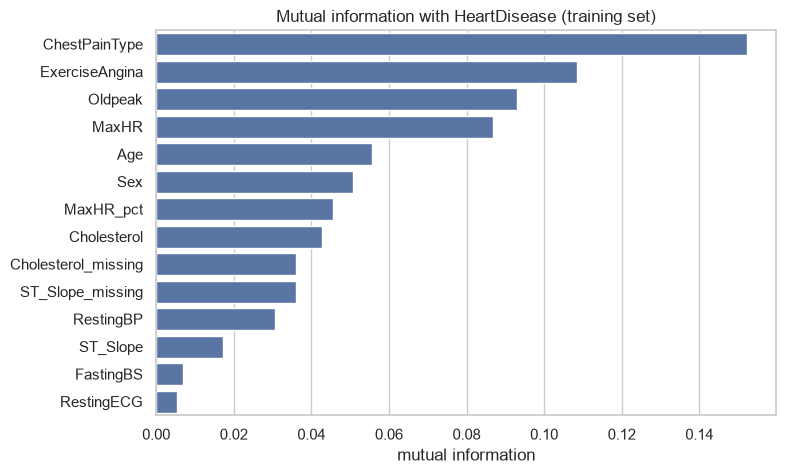

,MI
ChestPainType,0.152
ExerciseAngina,0.108
Oldpeak,0.093
MaxHR,0.087
Age,0.056
Sex,0.051
MaxHR_pct,0.046
Cholesterol,0.043
Cholesterol_missing,0.036
ST_Slope_missing,0.036


In [22]:
# Mutual information needs complete numbers: fill with TRAIN medians / modes, codes for categories
Xmi = train[NUM_FEATS + CAT_COLS + FLAG_FEATS].copy()
for col in NUM_FEATS:
    Xmi[col] = Xmi[col].fillna(Xmi[col].median())
for col in CAT_COLS:
    Xmi[col] = Xmi[col].fillna(Xmi[col].mode()[0]).cat.codes
discrete = [c not in NUM_FEATS for c in Xmi.columns]

mi = mutual_info_classif(Xmi, train[TARGET], discrete_features=discrete, random_state=SEED)
mi_tbl = pd.Series(mi, index=Xmi.columns, name="MI").sort_values(ascending=False).to_frame()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=mi_tbl["MI"], y=mi_tbl.index, color="#4C72B0", ax=ax)
ax.set_title("Mutual information with HeartDisease (training set)")
ax.set_xlabel("mutual information"); ax.set_ylabel("")
save_fig(fig, "fig_mutual_information"); plt.show()
mi_tbl.round(3)

In [23]:
# Redundancy check: are any two numeric features strongly correlated (|r| > 0.8)?
corr_num = train[NUM_FEATS].corr()
pairs = (corr_num.where(np.triu(np.ones(corr_num.shape, dtype=bool), k=1))
         .stack().rename("r").reset_index())
pairs["|r|"] = pairs["r"].abs()
pairs.sort_values("|r|", ascending=False).head(5).round(3)

,level_0,level_1,r,|r|
23,MaxHR,MaxHR_pct,0.952,0.952
3,Age,MaxHR,-0.367,0.367
4,Age,Oldpeak,0.266,0.266
1,Age,RestingBP,0.239,0.239
10,RestingBP,Oldpeak,0.193,0.193


**What the three methods say (training set, 734 patients):**
- **Strongest:** ChestPainType (χ² = 208.7, V = 0.53), ExerciseAngina (χ² = 157.2, V = 0.48), MaxHR (r = −0.40), Oldpeak (r = +0.38), ST_Slope (χ² = 64.2, V = 0.36) and Sex (V = 0.31).
- **Weakest:** RestingECG (V = 0.11), FastingBS (V = 0.15), RestingBP and Cholesterol (r ≈ 0.12). They are still significant at α = 0.05, but their effect is small.
- **ST_Slope: strong in chi-square, weak in MI.** The chi-square test leaves out the blanks. For MI we filled the 307 blanks with the most frequent value (Flat). Most of these blanks come from **Hungary** (189 of 293 Hungarian patients), where the disease rate is low, so filling them with "Flat" mixes low-risk patients into a high-risk group and hides the signal. **Lesson:** the imputation method changes what a feature can tell the model. In Part 2 we compare imputation methods and keep the `ST_Slope_missing` flag.

**Feature selection decision for Part 2:**
- All features are **kept for now**. A feature can be weak alone but useful together with others, and removing features using the training data before cross-validation would bias the CV results.
- **MaxHR and MaxHR_pct are strongly correlated** (they carry almost the same information). In Part 2 we keep only one of them for linear models.
- In Part 2, feature selection (top-k by chi-square / MI) is done **inside each cross-validation fold**, and we compare the full set with a reduced set.
- `Cholesterol_missing` is strongly related to the target, but mainly because of **Switzerland** (Section 2.3). Part 2 tests models **with and without** it (RQ3).

---
# 5. Exploratory Data Analysis (EDA)

EDA here is **descriptive** (we look, we do not fit anything), so it uses all 918 cleaned patients. Every graph starts with the **question** it answers.

### 5.1 Summary statistics

In [24]:
# Labels and colours used in every EDA graph: green = Normal, red = Disease
LABELS = {0: "Normal", 1: "Disease"}
PAL = {"Normal": "#55A868", "Disease": "#C44E52"}


desc = df[NUM_COLS].describe().T
desc["median"] = df[NUM_COLS].median()
desc["mode"] = df[NUM_COLS].mode().iloc[0]
desc["IQR"] = desc["75%"] - desc["25%"]
desc = desc.rename(columns={"25%": "Q1", "50%": "Q2", "75%": "Q3"})
desc[["count", "mean", "median", "mode", "std", "min", "Q1", "Q2", "Q3", "max", "IQR"]].round(2)

,count,mean,median,mode,std,min,Q1,Q2,Q3,max,IQR
Age,918.0,53.51,54.0,54.0,9.43,28.0,47.0,54.0,60.0,77.0,13.0
RestingBP,858.0,132.29,130.0,120.0,18.53,80.0,120.0,130.0,140.0,200.0,20.0
Cholesterol,717.0,246.87,240.0,220.0,58.56,85.0,210.0,240.0,277.0,603.0,67.0
MaxHR,863.0,137.54,140.0,150.0,25.94,60.0,120.0,140.0,157.0,202.0,37.0
Oldpeak,856.0,0.88,0.5,0.0,1.09,-2.6,0.0,0.5,1.5,6.2,1.5


In [25]:
# Mean of each numeric feature by diagnosis
df.groupby(TARGET)[NUM_COLS + ["MaxHR_pct"]].mean().rename(index={0: "Normal (0)", 1: "Disease (1)"}).round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,MaxHR_pct
HeartDisease,,,,,,
Normal (0),50.55,129.96,240.16,148.77,0.42,0.88
Disease (1),55.90,134.23,254.11,128.28,1.27,0.78


### 5.2 Q: Are the classes balanced, and is the disease rate the same in every hospital?

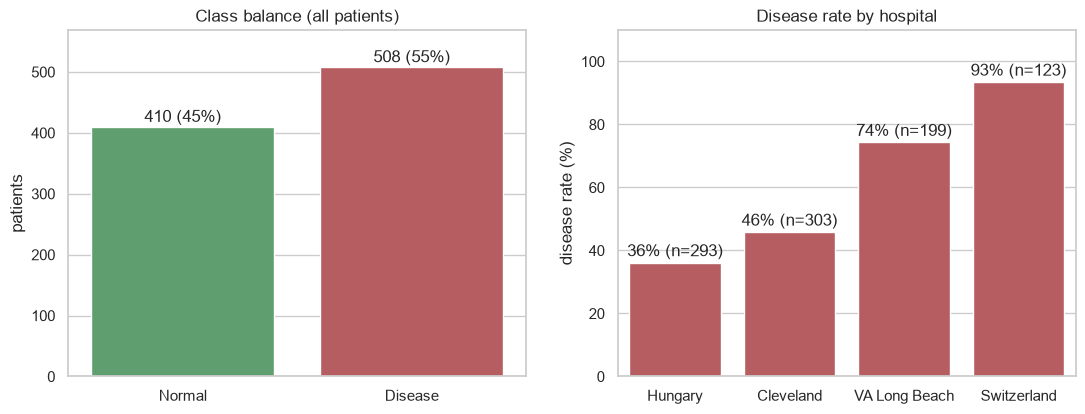

,patients,disease rate
hospital,,
Hungary,293,0.362
Cleveland,303,0.459
VA Long Beach,199,0.744
Switzerland,123,0.935


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cnt = df[TARGET].map(LABELS).value_counts().reindex(["Normal", "Disease"])
sns.barplot(x=list(cnt.index), y=cnt.values, hue=list(cnt.index), palette=PAL, legend=False, ax=axes[0])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 8, f"{v} ({v / len(df):.0%})", ha="center")
axes[0].set_title("Class balance (all patients)"); axes[0].set_ylabel("patients"); axes[0].set_xlabel("")
axes[0].set_ylim(0, cnt.max() * 1.12)

hosp = df.groupby("hospital", observed=True)[TARGET].agg(["size", "mean"]).sort_values("mean")
hosp.index = hosp.index.astype(str)          # plain strings keep the sorted order on the x-axis
sns.barplot(x=list(hosp.index), y=hosp["mean"].values * 100, color="#C44E52", ax=axes[1])
for i, (n, m) in enumerate(zip(hosp["size"], hosp["mean"])):
    axes[1].text(i, m * 100 + 2, f"{m:.0%} (n={n})", ha="center")
axes[1].set_title("Disease rate by hospital"); axes[1].set_ylabel("disease rate (%)"); axes[1].set_xlabel("")
axes[1].set_ylim(0, 110)
save_fig(fig, "fig_class_balance_hospital"); plt.show()
hosp.rename(columns={"size": "patients", "mean": "disease rate"}).round(3)

### 5.3 Q: Is missingness the same in every hospital?

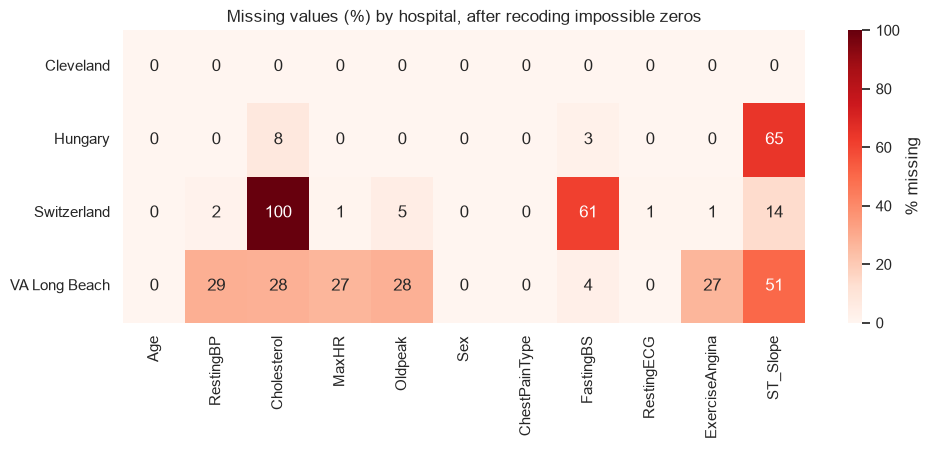

In [27]:
miss_pct = (df[NUM_COLS + CAT_COLS].isna().groupby(df["hospital"], observed=True).mean() * 100)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(miss_pct, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values (%) by hospital, after recoding impossible zeros"); ax.set_ylabel("")
save_fig(fig, "fig_missing_by_hospital"); plt.show()

### 5.4 Q: How are the numeric features distributed, and do they differ between patients with and without disease?

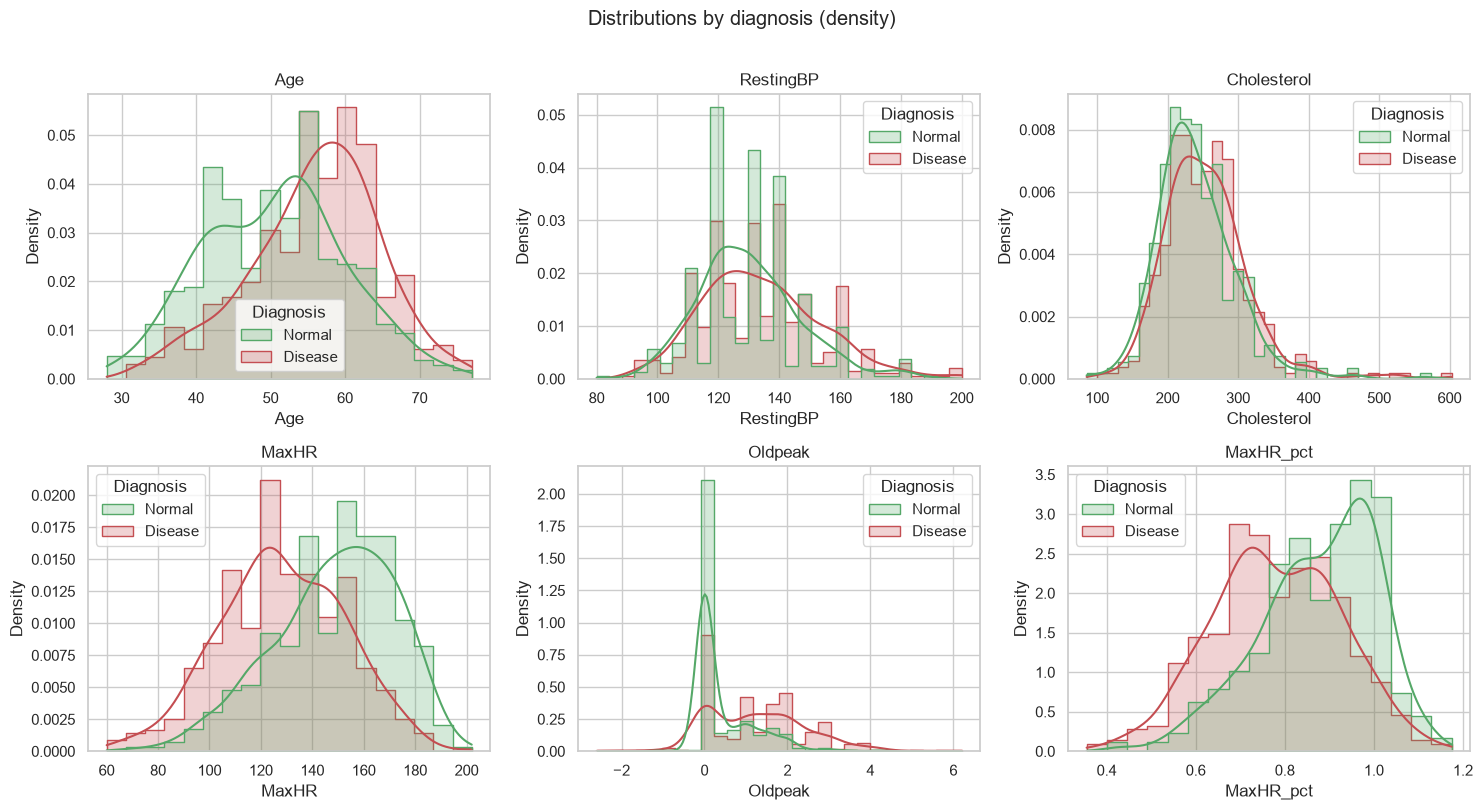

In [28]:
plot_df = df.assign(Diagnosis=df[TARGET].map(LABELS))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUM_COLS + ["MaxHR_pct"]):
    sns.histplot(data=plot_df, x=col, hue="Diagnosis", hue_order=["Normal", "Disease"], kde=True,
                 element="step", stat="density", common_norm=False, palette=PAL, ax=ax)
    ax.set_title(col)
fig.suptitle("Distributions by diagnosis (density)", y=1.01)
fig.tight_layout(); save_fig(fig, "fig_numeric_histograms"); plt.show()

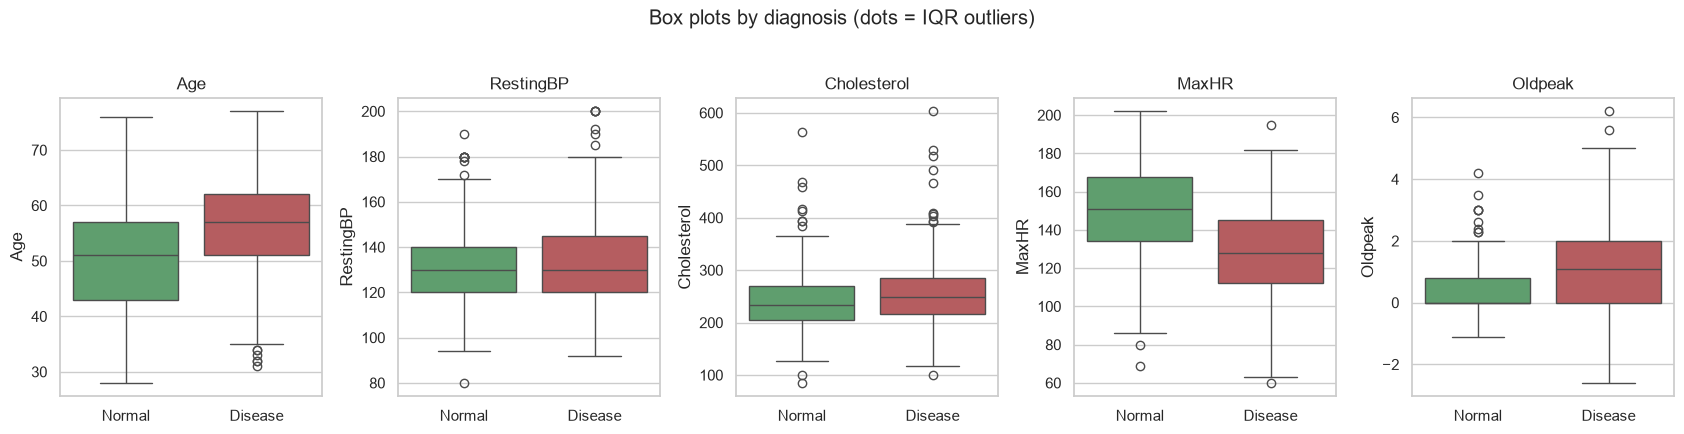

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4.2))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette={0: "#55A868", 1: "#C44E52"}, legend=False, ax=ax)
    ax.set_xticks([0, 1], ["Normal", "Disease"]); ax.set_xlabel(""); ax.set_title(col)
fig.suptitle("Box plots by diagnosis (dots = IQR outliers)", y=1.03)
fig.tight_layout(); save_fig(fig, "fig_numeric_boxplots"); plt.show()

### 5.5 Q: Is "Cholesterol = 0" a medical signal or a hospital shortcut?

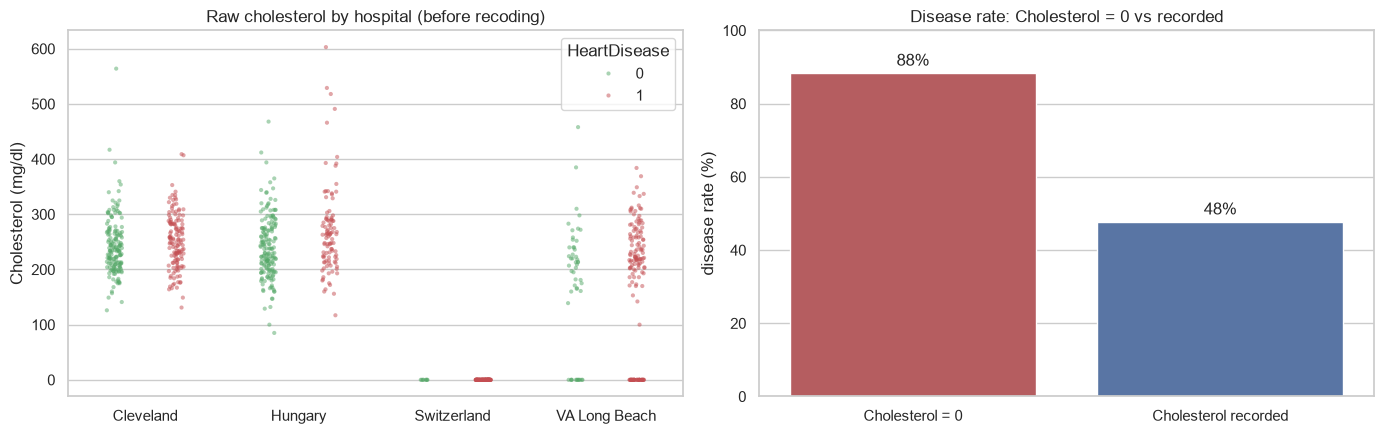

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.stripplot(data=df, x="hospital", y="Cholesterol_raw", hue=TARGET, palette={0: "#55A868", 1: "#C44E52"},
              dodge=True, alpha=0.5, size=3, ax=axes[0])
axes[0].set_title("Raw cholesterol by hospital (before recoding)"); axes[0].set_xlabel("")
axes[0].set_ylabel("Cholesterol (mg/dl)"); axes[0].legend(title="HeartDisease", loc="upper right")

grp = df.assign(group=np.where(df["Cholesterol_raw"] == 0, "Cholesterol = 0", "Cholesterol recorded"))
r = grp.groupby("group")[TARGET].mean() * 100
sns.barplot(x=r.index, y=r.values, hue=r.index, palette=["#C44E52", "#4C72B0"], legend=False, ax=axes[1])
for i, v in enumerate(r.values):
    axes[1].text(i, v + 2, f"{v:.0f}%", ha="center")
axes[1].set_ylim(0, 100); axes[1].set_ylabel("disease rate (%)"); axes[1].set_xlabel("")
axes[1].set_title("Disease rate: Cholesterol = 0 vs recorded")
fig.tight_layout(); save_fig(fig, "fig_cholesterol_shortcut"); plt.show()

### 5.6 Q: Which categories have the highest disease rate?

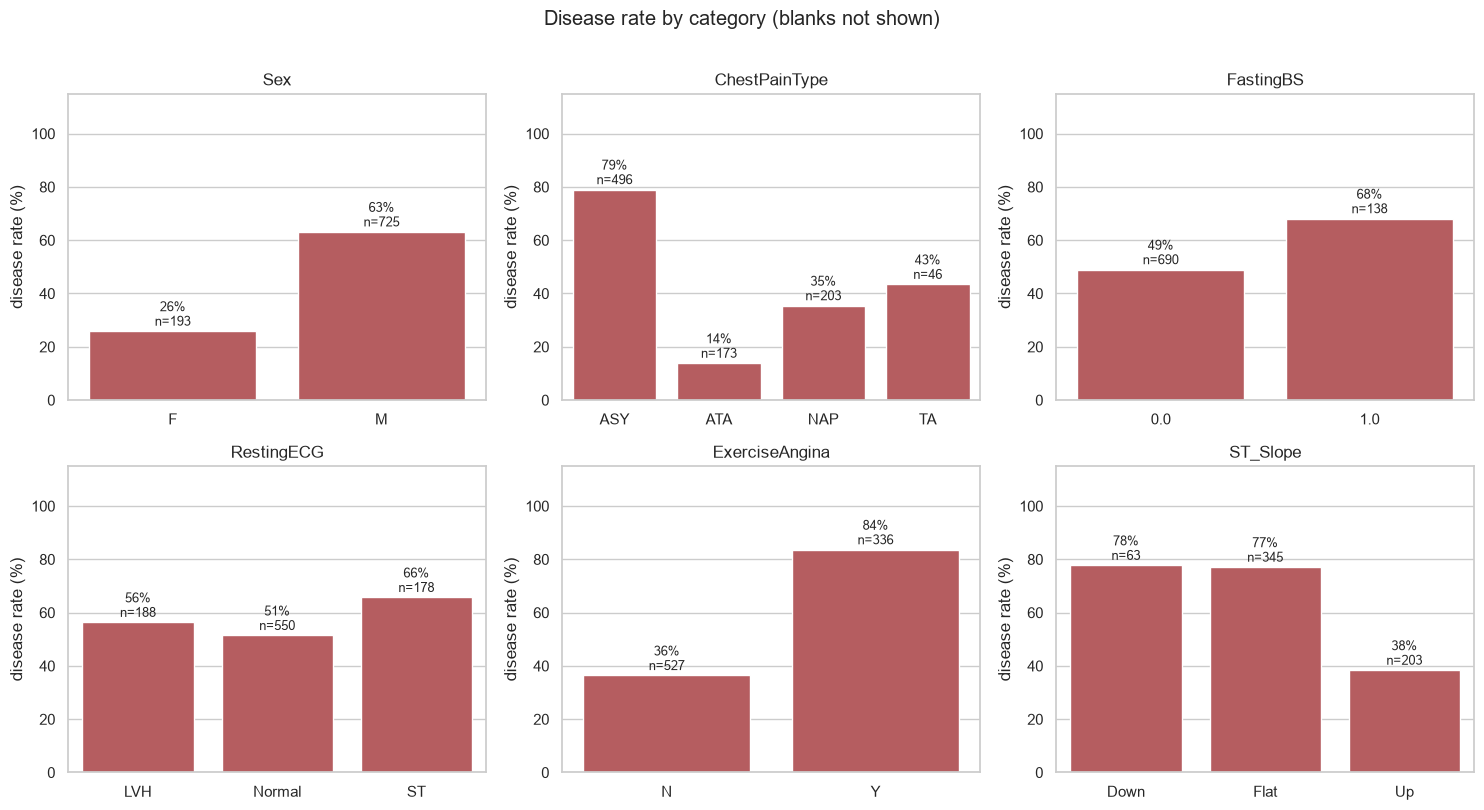

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, CAT_COLS):
    t = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    sns.barplot(x=t.index.astype(str), y=t["mean"] * 100, color="#C44E52", ax=ax)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m * 100 + 2, f"{m:.0%}\nn={n}", ha="center", fontsize=9)
    ax.set_ylim(0, 115); ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("disease rate (%)")
fig.suptitle("Disease rate by category (blanks not shown)", y=1.01)
fig.tight_layout(); save_fig(fig, "fig_categorical_rates"); plt.show()

### 5.7 Q: How strongly are the numeric features related to each other and to the target?

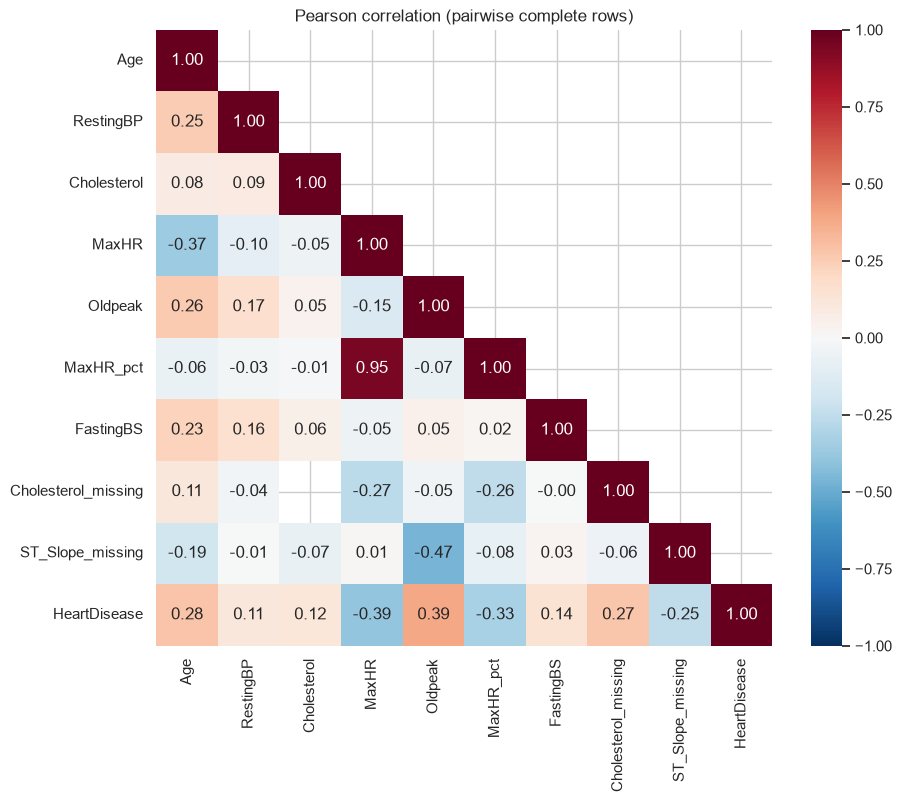

,r with HeartDisease
MaxHR,-0.393
Oldpeak,0.386
MaxHR_pct,-0.326
Age,0.282
Cholesterol_missing,0.274
ST_Slope_missing,-0.255
FastingBS,0.143
Cholesterol,0.119
RestingBP,0.115


In [32]:
corr_cols = NUM_COLS + ["MaxHR_pct", "FastingBS", "Cholesterol_missing", "ST_Slope_missing", TARGET]
corr = df[corr_cols].astype(float).corr(method="pearson")
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson correlation (pairwise complete rows)")
save_fig(fig, "fig_correlation_heatmap"); plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("r with HeartDisease")

### 5.8 Q: Do age and maximum heart rate together separate the two classes?

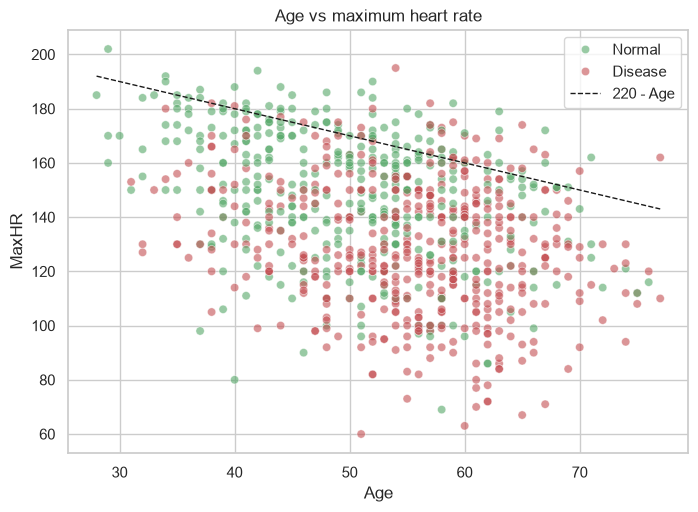

In [33]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="Age", y="MaxHR", hue=TARGET, palette={0: "#55A868", 1: "#C44E52"}, alpha=0.6, ax=ax)
ages = np.linspace(df["Age"].min(), df["Age"].max(), 50)
ax.plot(ages, 220 - ages, "k--", lw=1, label="220 - Age (predicted max)")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Normal", "Disease", "220 - Age"], title="")
ax.set_title("Age vs maximum heart rate")
save_fig(fig, "fig_age_maxhr_scatter"); plt.show()

### 5.9 Q: Do the feature distributions differ between hospitals (dataset shift)?

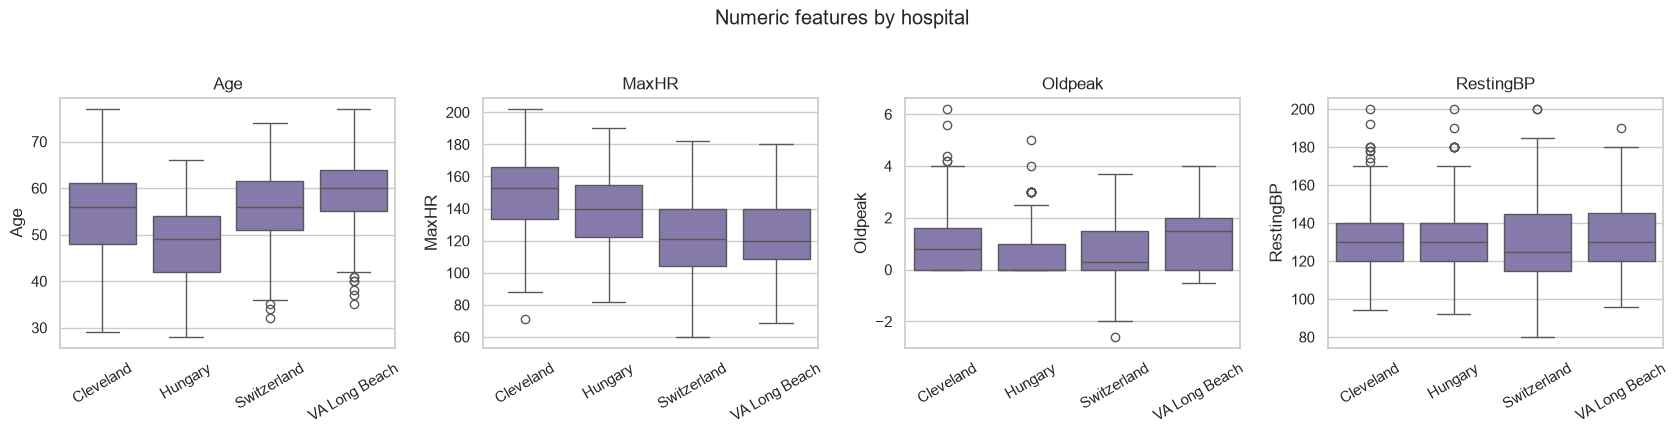

,Age,MaxHR,Oldpeak,RestingBP
hospital,,,,
Cleveland,56.0,153.0,0.8,130.0
Hungary,49.0,140.0,0.0,130.0
Switzerland,56.0,121.0,0.3,125.0
VA Long Beach,60.0,120.0,1.5,130.0


In [34]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, col in zip(axes, ["Age", "MaxHR", "Oldpeak", "RestingBP"]):
    sns.boxplot(data=df, x="hospital", y=col, color="#8172B2", ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
fig.suptitle("Numeric features by hospital", y=1.03)
fig.tight_layout(); save_fig(fig, "fig_features_by_hospital"); plt.show()
df.groupby("hospital", observed=True)[["Age", "MaxHR", "Oldpeak", "RestingBP"]].median().round(1)

---
# 6. Key Observations and Insights

**1. The data is clean in size but not in content.**
- 920 records → 2 duplicates removed → **918 unique patients** (508 disease, 410 normal = 55% / 45%). The classes are close to balanced, so accuracy is a fair metric, but our main metric stays **recall on the disease class**, because a missed patient is the most costly error in screening.

**2. The four hospitals are very different (dataset shift).**
- Disease rate: **Hungary 36%, Cleveland 46%, VA Long Beach 74%, Switzerland 93%**.
- VA patients are older (median age 60) and reach a lower maximum heart rate (median 120); Hungarian patients are the youngest (median 49).
- A random split mixes these hospitals. A model could learn "which hospital" instead of "which patient". This is why Part 2 also tests the model on a **hospital it has not seen** (leave-one-hospital-out, RQ2).

**3. Missing values depend on the hospital, and missingness itself is linked to the diagnosis.**
- Cleveland is complete. **Switzerland never recorded cholesterol** (all 123 values were 0). **Hungary** is missing ST_Slope for 189 of 293 patients. **VA** is missing RestingBP, MaxHR, ExerciseAngina and Oldpeak for about 27–29% of its patients.
- Hidden zeros were the biggest problem: **172 cholesterol values and 1 blood-pressure value were 0** and were recoded as missing. After recoding, Cholesterol is missing in 21.9% and ST_Slope in 33.4% of rows.
- Patients with **missing cholesterol have an 81% disease rate** (48% for the others); patients with **missing ST_Slope have 38%** (64% for the others). These rates come from the hospitals, not from medicine → **shortcut risk**, tested in Part 2 (RQ3: with and without `Cholesterol_missing`).

**4. The strongest signals come from chest pain and the exercise test.**
- **ChestPainType:** asymptomatic (ASY) patients have a **79%** disease rate; atypical angina (ATA) only **14%**. Many heart patients feel no typical chest pain, so "no symptoms" is not a safe sign.
- **ExerciseAngina:** 84% disease with exercise-induced pain vs 36% without.
- **ST_Slope:** Flat 77% and Down 78% vs Up 38%.
- **Oldpeak** is higher in disease (mean 1.27 vs 0.42) and **MaxHR** is lower (128 vs 149).
- **Sex:** men 63% vs women 26% disease rate (the data has 725 men and 193 women).

**5. Some classic risk factors are weak in this data.**
- RestingBP and Cholesterol have only r ≈ 0.12 with the target, and RestingECG and FastingBS have small Cramér's V (0.11 and 0.15). They stay in the feature set for Part 2, where feature selection is done inside cross-validation.

**6. Outliers are real patients, not errors.**
- IQR rule: RestingBP 27, Cholesterol 23, Oldpeak 16, MaxHR 2 values; |z| > 3: 22 values in total. All are clinically possible, so they are **kept**; scaling and tree models limit their effect.
- 12 negative Oldpeak values (ST elevation) are also real and kept.

**7. Redundancy.**
- MaxHR and our new feature MaxHR_pct are almost the same (r = 0.95). Linear models in Part 2 will use only one of them. No other numeric pair has |r| > 0.4.

**8. What Part 2 will do with these findings.**
- Use the saved stratified split (734 train / 184 test) and stratified 5-fold CV.
- Put imputation, encoding and scaling **inside one Pipeline** (fitted on training folds only) and compare median vs KNN imputation.
- Compare models with and without the missing-value flags (shortcut check), tune the decision threshold for **recall ≥ 0.90**, and test each hospital as an unseen hospital.

---
# 7. Saved Outputs for Part 2

| File | Content |
|---|---|
| `data/processed/heart_clean.csv` | 918 cleaned patients: impossible zeros → NaN, new features, hospital, split column (no imputation, no scaling) |
| `data/processed/split_indices.csv` | patient_id and train/test label, so Part 2 uses exactly the same split |
| `reports/figures/*.png` | all figures for the report |

In [35]:
out_cols = FEATURES + ["hospital", TARGET, "split"]
clean = df[out_cols].copy()
clean.to_csv(PROC / "heart_clean.csv")
df[["split"]].to_csv(PROC / "split_indices.csv")

print("Saved:", PROC / "heart_clean.csv", clean.shape)
print("Saved:", PROC / "split_indices.csv", df["split"].value_counts().to_dict())
print("Figures:", sorted(p.name for p in FIG.glob("*.png")))

Saved: ..\data\processed\heart_clean.csv (918, 17)
Saved: ..\data\processed\split_indices.csv {'train': 734, 'test': 184}
Figures: ['fig_age_maxhr_scatter.png', 'fig_categorical_rates.png', 'fig_cholesterol_shortcut.png', 'fig_class_balance_hospital.png', 'fig_correlation_heatmap.png', 'fig_features_by_hospital.png', 'fig_missing_by_hospital.png', 'fig_mutual_information.png', 'fig_numeric_boxplots.png', 'fig_numeric_histograms.png']
